In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from sklearn.model_selection import train_test_split

import joblib

In [2]:
df = pd.read_csv(
    "../data/raw/PS_20174392719_1491204439457_log.csv"
)

df = df.drop(
    columns=["nameOrig", "nameDest", "isFlaggedFraud"]
)

df["errorBalanceOrig"] = (
    df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]
)

df["errorBalanceDest"] = (
    df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
)

df = pd.get_dummies(
    df,
    columns=["type"],
    dtype=int
)

print(df.shape)

(6362620, 14)


In [3]:
X = df.drop(columns=["isFraud"])
y = df["isFraud"]

train_end = df["step"].quantile(0.70)
validation_end = df["step"].quantile(0.85)

train_mask = df["step"] <= train_end

validation_mask = (
    (df["step"] > train_end) &
    (df["step"] <= validation_end)
)

test_mask = df["step"] > validation_end

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[validation_mask]
y_val = y.loc[validation_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

In [4]:
print("Training fraud distribution:")
print(y_train.value_counts())

print("\nFraud percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training fraud distribution:
isFraud
0    4459944
1       3643
Name: count, dtype: int64

Fraud percentages:
isFraud
0    99.918384
1     0.081616
Name: proportion, dtype: float64


In [5]:
sample_size = min(500_000, len(X_train))

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=sample_size,
    stratify=y_train,
    random_state=42
)

print("Training sample:", X_train_sample.shape)

print("\nClass distribution:")
print(y_train_sample.value_counts())

Training sample: (500000, 13)

Class distribution:
isFraud
0    499592
1       408
Name: count, dtype: int64


In [6]:
model = Pipeline([
    ("scaler", StandardScaler()),
    
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

In [7]:
print("Training FraudShield AI...")

model.fit(
    X_train_sample,
    y_train_sample
)

print("Training completed successfully!")

Training FraudShield AI...
Training completed successfully!


In [8]:
y_pred = model.predict(X_val)

y_prob = model.predict_proba(X_val)[:, 1]

In [9]:
print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 fraud probabilities:")
print(y_prob[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 fraud probabilities:
[1.01668361e-04 1.31176972e-04 2.18156486e-27 1.08516135e-04
 3.74197969e-25 5.48173742e-07 3.86323380e-07 7.24179082e-09
 8.40726454e-09 8.99761986e-05]


In [10]:
precision = precision_score(y_val, y_pred)

recall = recall_score(y_val, y_pred)

f1 = f1_score(y_val, y_pred)

roc_auc = roc_auc_score(y_val, y_prob)

pr_auc = average_precision_score(y_val, y_prob)

print("FRAUDSHIELD AI - MODEL PERFORMANCE")

print("--------------------------------")

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

print("ROC-AUC:", roc_auc)

print("PR-AUC:", pr_auc)

FRAUDSHIELD AI - MODEL PERFORMANCE
--------------------------------
Precision: 0.017866845654744782
Recall: 0.9911347517730497
F1 Score: 0.03510093874603623
ROC-AUC: 0.994834043977636
PR-AUC: 0.6343134902086454


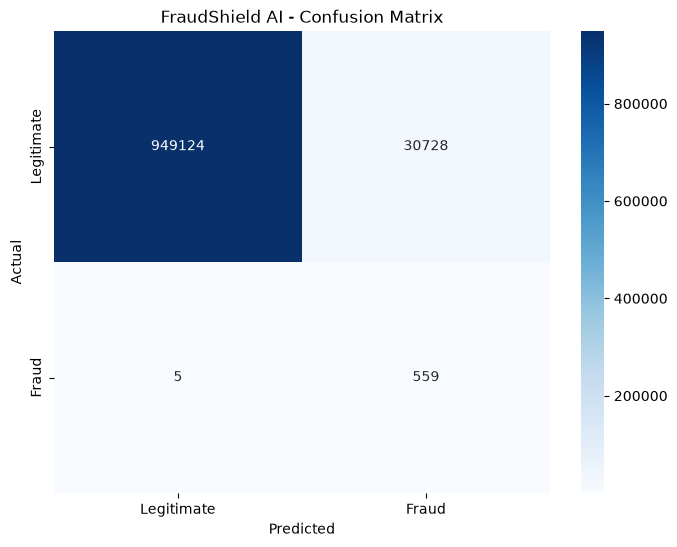

In [11]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("FraudShield AI - Confusion Matrix")

plt.show()

In [12]:
joblib.dump(
    model,
    "../models/logistic_regression.pkl"
)

print("Model saved successfully!")

Model saved successfully!
